
# Loan Approval Prediction

## InternSpark - Task 2

### Project Objective
The objective of this project is to develop a supervised machine learning model that predicts whether a loan application is likely to be approved or rejected.

### Main Activities
1. Data loading and exploration
2. Data cleaning and preprocessing
3. Handling missing values
4. Categorical encoding and numerical scaling
5. Handling class imbalance using SMOTE
6. Training multiple machine learning models
7. Comparing model performance
8. Evaluating precision, recall, F1-score and ROC-AUC
9. Business interpretation and threshold selection

### Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn and Imbalanced-learn.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw"

OUTPUT_PATH = PROJECT_ROOT / "outputs"
FIGURE_PATH = PROJECT_ROOT / "figures"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"

for folder in [OUTPUT_PATH, FIGURE_PATH, PROCESSED_PATH]:
    folder.mkdir(parents=True, exist_ok=True)

csv_files = list(DATA_PATH.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found. Put your Kaggle dataset inside data/raw."
    )

if len(csv_files) > 1:
    print("CSV files found:", [f.name for f in csv_files])

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print("File:", csv_files[0].name)
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
File: loan_prediction.csv
Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
%pip install imbalanced-learn


In [5]:

print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Number of rows and columns: (614, 13)

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64


Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP002990,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


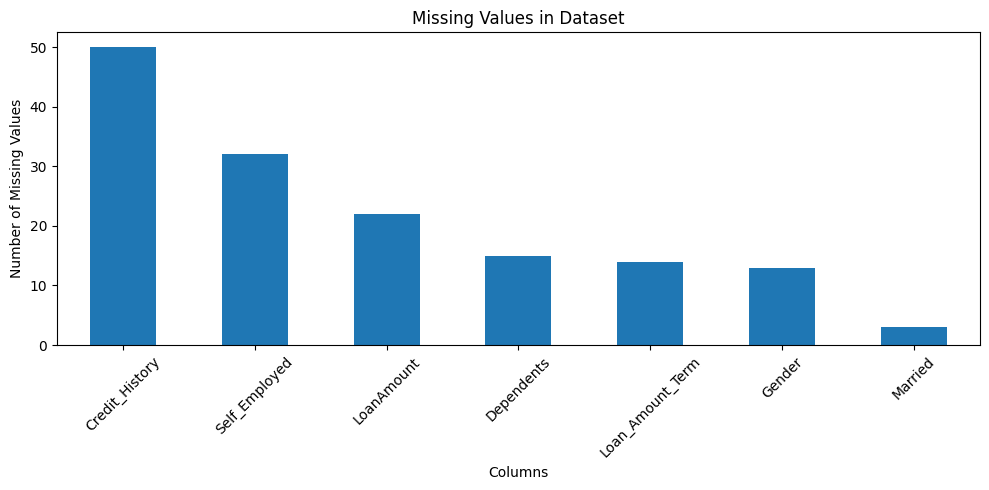

In [6]:

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(10, 5))

missing_values.sort_values(ascending=False).plot(
    kind="bar"
)

plt.title("Missing Values in Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "missing_values.png",
    dpi=150
)

plt.show()


In [7]:

print("Available columns:")
print(df.columns.tolist())

TARGET_COLUMN = "Loan_Status"

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        "Loan_Status was not found. "
        "Check your column names and update TARGET_COLUMN."
    )

print("\nTarget column:", TARGET_COLUMN)

print("\nTarget distribution:")
display(df[TARGET_COLUMN].value_counts())


Available columns:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Target column: Loan_Status

Target distribution:


Loan_Status
Y    422
N    192
Name: count, dtype: int64

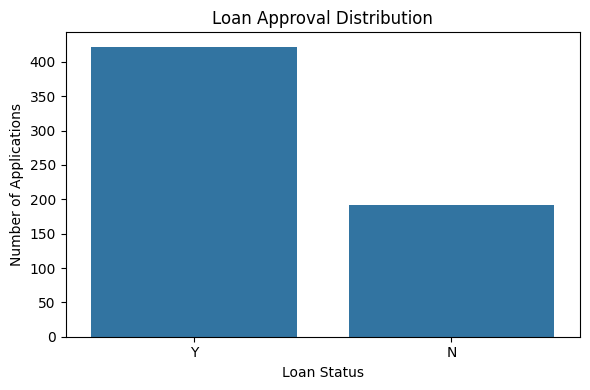

In [8]:

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x=TARGET_COLUMN
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "class_distribution.png",
    dpi=150
)

plt.show()


In [9]:

df = df.copy()

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing target values
df = df.dropna(subset=[TARGET_COLUMN])

# Remove unnecessary ID column
for col in ["Loan_ID", "LoanID", "ID"]:
    if col in df.columns:
        df = df.drop(columns=[col])

# Separate input features and target
X = df.drop(columns=[TARGET_COLUMN])

# Convert target into numerical format
target_mapping = {
    "Y": 1,
    "N": 0,
    "Yes": 1,
    "No": 0,
    "Approved": 1,
    "Rejected": 0
}

y_text = df[TARGET_COLUMN].astype(str).str.strip()

if set(y_text.unique()).issubset(target_mapping.keys()):
    y = y_text.map(target_mapping).astype(int)
else:
    raise ValueError(
        "Unexpected target labels: "
        + str(y_text.unique())
        + ". Update target_mapping after checking the data."
    )

print("Data cleaning completed!")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())


Data cleaning completed!
Features shape: (614, 11)
Target shape: (614,)

Target values:
Loan_Status
1    422
0    192
Name: count, dtype: int64


In [10]:

# First split: 80% development data, 20% final test data

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: training and validation data

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.25,
    random_state=42,
    stratify=y_trainval
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)


Training data: (368, 11)
Validation data: (123, 11)
Testing data: (123, 11)


In [11]:

# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

print("Preprocessing pipeline created successfully!")


Numerical columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
Preprocessing pipeline created successfully!


In [12]:

print("Original training class distribution:")
print(y_train.value_counts())

minority_count = y_train.value_counts().min()

if minority_count < 2:
    raise ValueError(
        "Not enough minority-class examples for SMOTE."
    )

smote_neighbors = min(5, minority_count - 1)

smote = SMOTE(
    random_state=42,
    k_neighbors=smote_neighbors
)

print("\nSMOTE is ready!")
print("Number of neighbours:", smote_neighbors)


Original training class distribution:
Loan_Status
1    253
0    115
Name: count, dtype: int64

SMOTE is ready!
Number of neighbours: 5


In [13]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

print("Models created successfully!")

for name in models:
    print(name)


Models created successfully!
Logistic Regression
Decision Tree
Random Forest


In [14]:

from sklearn.base import clone

pipelines = {}
validation_probabilities = {}
results = []

for name, model in models.items():

    pipeline = ImbPipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("smote", clone(smote)),
        ("classifier", clone(model))
    ])

    print(f"\nTraining {name}...")

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    predictions = (
        probabilities >= 0.50
    ).astype(int)

    validation_probabilities[name] = probabilities
    pipelines[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

print("\nAll models trained successfully!")



Training Logistic Regression...

Training Decision Tree...

Training Random Forest...

All models trained successfully!


In [15]:

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by="F1 Score",
    ascending=False
)

display(comparison.round(3))

comparison.to_csv(
    OUTPUT_PATH / "model_comparison.csv",
    index=False
)

best_model_name = comparison.iloc[0]["Model"]

print("\nBest model based on validation F1-score:")
print(best_model_name)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.740,0.771,0.881,0.822,0.722
1,Decision Tree,0.715,0.747,0.881,0.809,0.721
0,Logistic Regression,0.683,0.785,0.738,0.761,0.697



Best model based on validation F1-score:
Random Forest


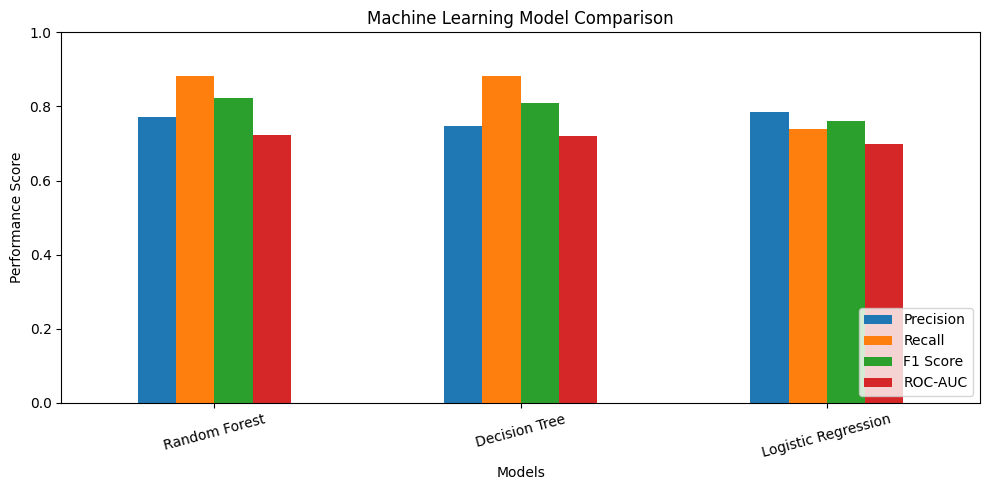

In [16]:

metrics = comparison.set_index("Model")[
    ["Precision", "Recall", "F1 Score", "ROC-AUC"]
]

metrics.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "model_comparison.png",
    dpi=150
)

plt.show()


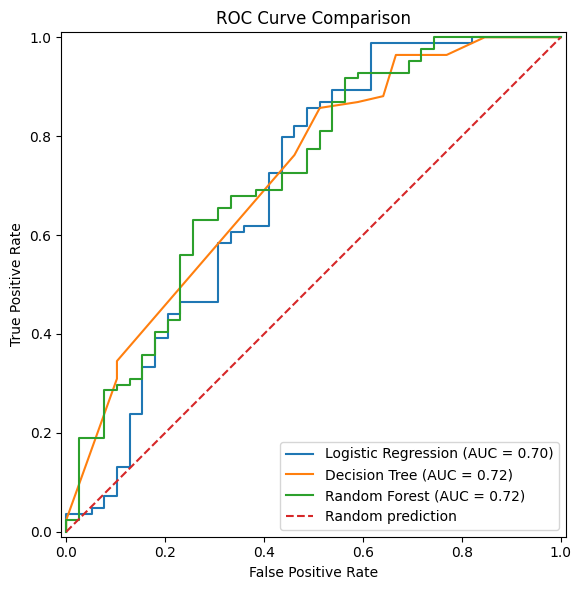

In [17]:

plt.figure(figsize=(8, 6))

for name, probabilities in validation_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_val,
        probabilities,
        name=name,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random prediction"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "roc_curve.png",
    dpi=150
)

plt.show()


In [18]:

best_pipeline = pipelines[best_model_name]

best_validation_probabilities = (
    validation_probabilities[best_model_name]
)

from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_val,
        best_validation_probabilities
    )
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    /
    (
        precision_values[:-1]
        + recall_values[:-1]
        + 1e-12
    )
)

best_threshold = float(
    thresholds[np.argmax(f1_values)]
)

print("Selected threshold:", round(best_threshold, 3))
print("Selected model:", best_model_name)


Selected threshold: 0.232
Selected model: Random Forest


In [19]:

test_probabilities = best_pipeline.predict_proba(
    X_test
)[:, 1]

# Evaluate at the standard threshold
default_predictions = (
    test_probabilities >= 0.50
).astype(int)

# Evaluate at the selected validation threshold
final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

def evaluate_model(y_true, predictions, probabilities, label):

    return {
        "Threshold": label,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        )
    }

final_results = pd.DataFrame([
    evaluate_model(
        y_test,
        default_predictions,
        test_probabilities,
        "0.50"
    ),
    evaluate_model(
        y_test,
        final_predictions,
        test_probabilities,
        str(round(best_threshold, 3))
    )
])

display(final_results.round(3))

final_results.to_csv(
    OUTPUT_PATH / "final_test_metrics.csv",
    index=False
)


,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0.50,0.821,0.839,0.918,0.876,0.804
1,0.232,0.772,0.761,0.976,0.856,0.804


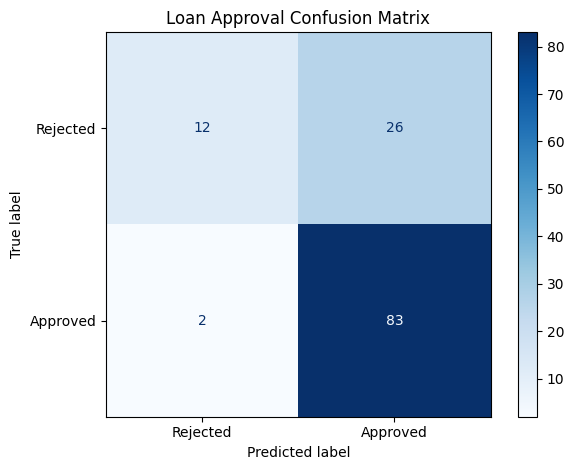


Classification Report:
              precision    recall  f1-score   support

    Rejected       0.86      0.32      0.46        38
    Approved       0.76      0.98      0.86        85

    accuracy                           0.77       123
   macro avg       0.81      0.65      0.66       123
weighted avg       0.79      0.77      0.73       123



In [20]:

cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=[0, 1]
)

display_labels = [
    "Rejected",
    "Approved"
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Loan Approval Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "confusion_matrix.png",
    dpi=150
)

plt.show()

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=display_labels,
        zero_division=0
    )
)


In [21]:

tn, fp, fn, tp = cm.ravel()

print("BUSINESS INTERPRETATION")
print("-----------------------")

print(f"Correctly identified rejected applications: {tn}")
print(f"Correctly identified approved applications: {tp}")

print(f"Incorrect approval predictions: {fp}")
print(f"Missed approved applications: {fn}")

print("\nBusiness Insights:")

print(
    "False positives may increase lending risk "
    "if incorrect approval predictions are acted upon."
)

print(
    "False negatives may cause eligible applicants "
    "to miss potential loan opportunities."
)

print(
    "The bank should select a decision threshold "
    "based on its risk tolerance and business costs."
)


BUSINESS INTERPRETATION
-----------------------
Correctly identified rejected applications: 12
Correctly identified approved applications: 83
Incorrect approval predictions: 26
Missed approved applications: 2

Business Insights:
False positives may increase lending risk if incorrect approval predictions are acted upon.
False negatives may cause eligible applicants to miss potential loan opportunities.
The bank should select a decision threshold based on its risk tolerance and business costs.


In [22]:

joblib.dump(
    best_pipeline,
    OUTPUT_PATH / "best_model.joblib"
)

metadata = {
    "model_name": best_model_name,
    "threshold": best_threshold,
    "target_column": TARGET_COLUMN,
    "positive_class": "Approved"
}

joblib.dump(
    metadata,
    OUTPUT_PATH / "model_metadata.joblib"
)

print("Best model saved successfully!")
print("Saved in:", OUTPUT_PATH)


Best model saved successfully!
Saved in: c:\projects\Loan-Approval-Prediction\outputs


In [23]:

print("=" * 50)
print("LOAN APPROVAL PREDICTION - PROJECT SUMMARY")
print("=" * 50)

print("Dataset records:", len(df))
print("Features used:", X.shape[1])

print("Models compared:")
for name in models:
    print("-", name)

print("\nSelected model:", best_model_name)
print("Suggested threshold:", round(best_threshold, 3))

print("\nFinal test results:")
display(final_results.round(3))

print("\nProject execution completed successfully!")


LOAN APPROVAL PREDICTION - PROJECT SUMMARY
Dataset records: 614
Features used: 11
Models compared:
- Logistic Regression
- Decision Tree
- Random Forest

Selected model: Random Forest
Suggested threshold: 0.232

Final test results:


,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0.50,0.821,0.839,0.918,0.876,0.804
1,0.232,0.772,0.761,0.976,0.856,0.804



Project execution completed successfully!
